In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [5]:
df = pd.read_csv('/Users/sachinchoudhary/Developer/ML/data/placement.csv')
df.head()

,cgpa,placement_exam_marks,placed
0,7.19,26.0,1
1,7.46,38.0,1
2,7.54,40.0,1
3,6.42,8.0,1
4,7.23,17.0,0


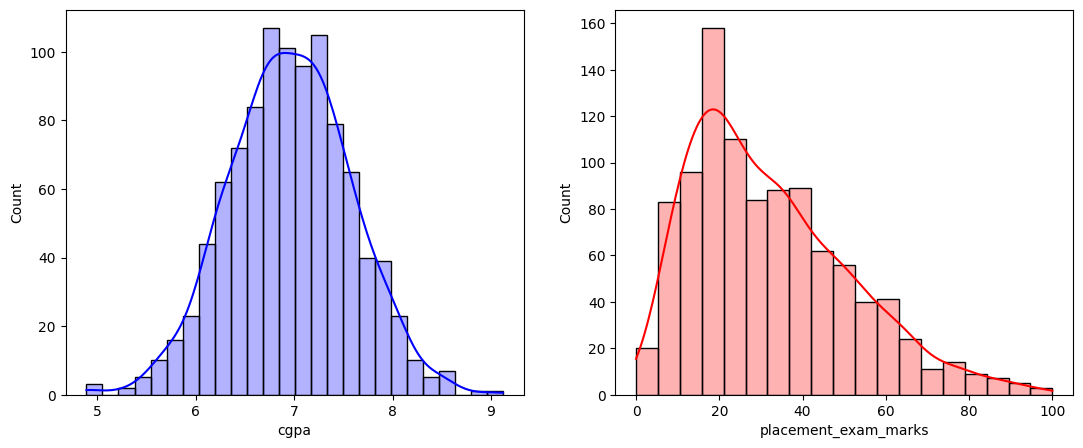

In [14]:
plt.figure(figsize=(13,5))

plt.subplot(1,2,1)
sns.histplot(df['cgpa'],color='blue',kde=True, alpha=0.3)

plt.subplot(1,2,2)
sns.histplot(df['placement_exam_marks'],color='red',kde=True, alpha=0.3)

plt.show()

In [16]:
print('Mean value of cgpa', df['cgpa'].mean())
print('Std value of cgpa',df['cgpa'].std())
print('MIn value of cgpa',df['cgpa'].min())
print('Max value of cgpa',df['cgpa'].max())

Mean value of cgpa 6.96124
Std value of cgpa 0.6158978751323896
MIn value of cgpa 4.89
Max value of cgpa 9.12


In [17]:
print('Highest allowed ->', df['cgpa'].mean() + 3*df['cgpa'].std())
print('Lowest allowed ->', df['cgpa'].mean() - 3*df['cgpa'].std())

Highest allowed -> 8.808933625397168
Lowest allowed -> 5.113546374602832


# Trimming

In [18]:
df[(df['cgpa'] > 8.80) | (df['cgpa'] < 5.11)]

,cgpa,placement_exam_marks,placed
485,4.92,44.0,1
995,8.87,44.0,1
996,9.12,65.0,1
997,4.89,34.0,0
999,4.90,10.0,1


In [20]:
new_df = df[(df['cgpa'] < 8.80) & (df['cgpa'] > 5.11)]
new_df

,cgpa,placement_exam_marks,placed
0,7.19,26.0,1
1,7.46,38.0,1
2,7.54,40.0,1
3,6.42,8.0,1
4,7.23,17.0,0
...,...,...,...
991,7.04,57.0,0
992,6.26,12.0,0
993,6.73,21.0,1
994,6.48,63.0,0


In [21]:
df['cgpa_zscore'] = (df['cgpa'] - df['cgpa'].mean())/ df['cgpa'].std()
df.head()

,cgpa,placement_exam_marks,placed,cgpa_zscore
0,7.19,26.0,1,0.371425
1,7.46,38.0,1,0.809810
2,7.54,40.0,1,0.939701
3,6.42,8.0,1,-0.878782
4,7.23,17.0,0,0.436371


In [23]:
new_df = df[(df['cgpa_zscore'] > -3) & (df['cgpa_zscore'] < 3)]
new_df

,cgpa,placement_exam_marks,placed,cgpa_zscore
0,7.19,26.0,1,0.371425
1,7.46,38.0,1,0.809810
2,7.54,40.0,1,0.939701
3,6.42,8.0,1,-0.878782
4,7.23,17.0,0,0.436371
...,...,...,...,...
991,7.04,57.0,0,0.127878
992,6.26,12.0,0,-1.138565
993,6.73,21.0,1,-0.375452
994,6.48,63.0,0,-0.781363


# Capping

In [24]:
upper_limit = df['cgpa'].mean() + 3*df['cgpa'].std()
lower_limit = df['cgpa'].mean() - 3*df['cgpa'].std()

In [26]:
df['cgpa'] = np.where(
    df['cgpa'] > upper_limit,
    upper_limit, 
    np.where(df['cgpa'] < lower_limit, 
             lower_limit, 
             df['cgpa']
        )
    )
df.sample(5)

,cgpa,placement_exam_marks,placed,cgpa_zscore
159,6.70,22.0,0,-0.424161
262,7.19,10.0,1,0.371425
101,6.48,26.0,1,-0.781363
457,6.58,20.0,0,-0.618999
119,7.00,39.0,0,0.062933


In [28]:
df['cgpa'].describe()

count    1000.000000
mean        6.961499
std         0.612688
min         5.113546
25%         6.550000
50%         6.960000
75%         7.370000
max         8.808934
Name: cgpa, dtype: float64